In [1]:
import pymc as pm
import arviz as az
import numpy as np
import scipy
import scipy.stats as stats
from scipy.optimize import minimize
import pandas as pd
import matplotlib.pyplot as plt
import numdifftools as nd
import pymc as pm
import arviz as az

In [2]:
data = pd.read_csv("milk.csv", sep=";")
milk = data[["kcal.per.g", "neocortex.perc", "mass"]]
len(milk)

29

In [3]:
milk = milk.dropna(subset=["mass", "kcal.per.g", "neocortex.perc"]).copy()
milk["mass"] = (np.log(milk["mass"]) - np.log(milk["mass"]).mean()) / np.log(milk["mass"]).std()
milk["kcal.per.g"] = (milk["kcal.per.g"] - milk["kcal.per.g"].mean()) / milk["kcal.per.g"].std()
milk["neocortex.perc"] = (milk["neocortex.perc"] - milk["neocortex.perc"].mean()) / milk["neocortex.perc"].std()
len(milk)

17

In [4]:
cols = ["mass", "kcal.per.g", "neocortex.perc"]

print(milk[cols].corr().to_string())

                    mass  kcal.per.g  neocortex.perc
mass            1.000000   -0.354264        0.750376
kcal.per.g     -0.354264    1.000000        0.155458
neocortex.perc  0.750376    0.155458        1.000000


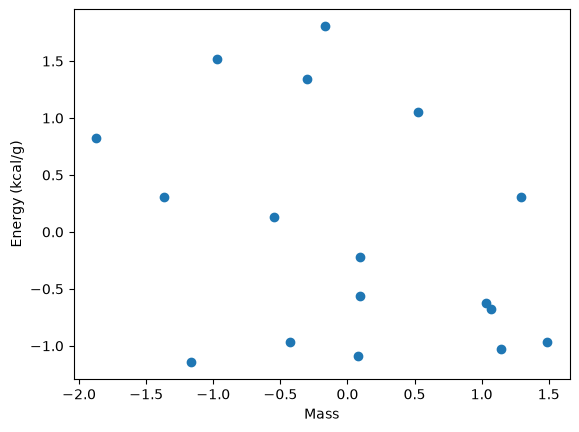

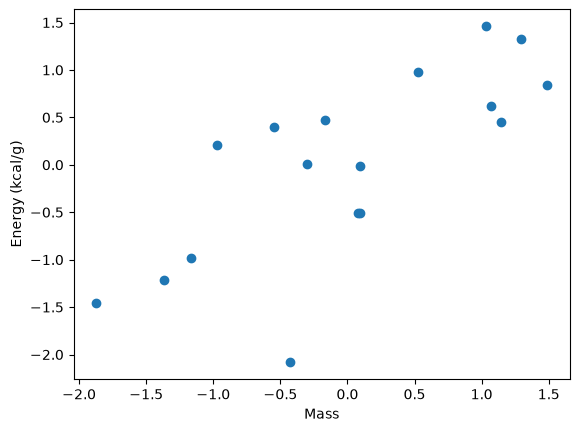

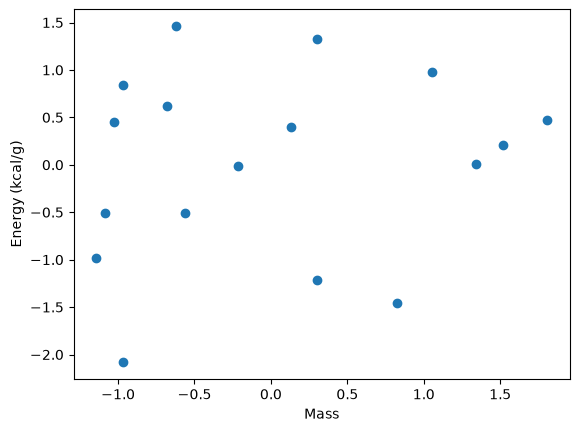

In [5]:
plt.scatter(x=milk["mass"], y=milk["kcal.per.g"])
plt.xlabel("Mass")
plt.ylabel("Energy (kcal/g)")
plt.show()

plt.scatter(x=milk["mass"], y=milk["neocortex.perc"])
plt.xlabel("Mass")
plt.ylabel("Energy (kcal/g)")
plt.show()

plt.scatter(x=milk["kcal.per.g"], y=milk["neocortex.perc"])
plt.xlabel("Mass")
plt.ylabel("Energy (kcal/g)")
plt.show()

In [6]:
kcal = milk["kcal.per.g"].to_numpy()
neo = milk["neocortex.perc"].to_numpy()
mass = milk["mass"].to_numpy()

### Model 1 — Neocortex only

In [7]:
with pm.Model() as model_n:
    alpha = pm.Normal("alpha", 0, 0.2)
    beta_n = pm.Normal("beta_n", 0, 0.5)
    sigma = pm.Exponential("sigma", 1)
    mu_i = alpha + beta_n * neo
    kcal_n = pm.Normal("kcal_n", mu=mu_i, sigma=sigma, observed=kcal)

    trace_n = pm.sample(draws=1000, tune=1000, chains=4)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta_n, sigma]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 8 seconds.


### Model 2 — Maternal mass only

In [8]:
with pm.Model() as model_m:
    alpha = pm.Normal("alpha", 0, 0.2)
    beta_m = pm.Normal("beta_m", 0, 0.5)
    sigma = pm.Exponential("sigma", 1)
    mu_i = alpha + beta_m * mass
    kcal_m = pm.Normal("kcal_n", mu=mu_i, sigma=sigma, observed=kcal)

    trace_m = pm.sample(draws=1000, tune=1000, chains=4)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta_m, sigma]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 7 seconds.


### Model 3 — Both predictors

In [9]:
with pm.Model() as model_m_n:
    alpha = pm.Normal("alpha", 0, 0.2)
    beta_m = pm.Normal("beta_m", 0, 0.5)
    beta_n = pm.Normal("beta_n", 0, 0.5)
    sigma = pm.Exponential("sigma", 1)
    mu_i = alpha + beta_m * mass + beta_n * neo
    kcal_m = pm.Normal("kcal_n", mu=mu_i, sigma=sigma, observed=kcal)

    trace_m_n = pm.sample(draws=1000, tune=1000, chains=4)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta_m, beta_n, sigma]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 8 seconds.


In [10]:
import arviz as az

print("Model 1:")
print(az.summary(trace_n)[["mean", "sd"]])

print("Model 2:")
print(az.summary(trace_m)[["mean", "sd"]])

print("Model 3:")
print(az.summary(trace_m_n)[["mean", "sd"]])

Model 1:
         mean     sd
alpha   0.001  0.153
beta_n  0.120  0.226
sigma   1.038  0.191
Model 2:
         mean     sd
alpha   0.003  0.152
beta_m -0.280  0.219
sigma   0.987  0.180
Model 3:
         mean     sd
alpha   0.004  0.140
beta_m -0.672  0.261
beta_n  0.567  0.262
sigma   0.815  0.171


In [11]:
comparison = pd.DataFrame(
    {
        "Marginal": [
            trace_n.posterior["beta_n"].mean().item(),
            trace_m.posterior["beta_m"].mean().item(),
        ],
        "Conditional": [
            trace_m_n.posterior["beta_n"].mean().item(),
            trace_m_n.posterior["beta_m"].mean().item(),
        ],
    },
    index=["Neocortex", "Mass"],
)

print(comparison)

           Marginal  Conditional
Neocortex  0.120471     0.567352
Mass      -0.279502    -0.671996
